# Homework 4
> **Author:** Elias Schweighuber
> **Course:** HEO


## 1. Encodings
Make a literature search, regarding encodings for the job shop scheduling problem and the
vehicle routing problem. Explain three different encoding strategies. Does the different encoding
strategies influence the search space?

### Job Shop Scheduling Problem
1. **Operation-List Encoding:**
   - A solution is a permutation of length n * m (for n jobs and m machines)
   - The k-th appearance of a job refers to the k-th operation of that job.
   - This Encoding respects the sequence of jobs and machines
2. **Job-List Encoding:**
   - A solution is a simple permutation of the n jobs (length n)
   - A decoder schedules all operations of the first job in the list, then for the next job and so on.
3. **Machine-List Encoding:**
   - A solution is a permutation of m machines (length m)
   - Each machine has an ordered list, that defines the processing sequence of the operations.

### Vehicle Routing Problem
1. **Permutation Without Delimiters:**
   - Contains two parallel vectors.
      - One lists the sequence of customers
      - The other maps each customer to a vehicle
2. **Direct Representation with Delimiters:**
   - A single linear array for all customers, that represents the routes for each vehicle
   - e.g [dummy, 1, 4, Dummy, 2, 3, 5, Dummy]
      - This would mean, that vehicle one visits customer one and four, vehicle two visits 2, 3 and 5...
3. **Cluster-First, Route-Second Representation:**
   - The encoding assigns customers into clusters (one cluster per vehicle) and then makes a routine, that orders the stops within each cluster.


### Do different encoding strategies influence the search space?
- **Yes:**
  - **Size of the search space:** In JSSP, a job-list encoding has n! states, whereas an operation-list encoding has (n * m)!/(m!)^n states.
    - n=3 m=3 -> Job-List encoding would have a search space of 6, Operation-List encoding would have a search space of 1680
  - Some encodings may have redundant solutions, or cannot represent all optimal solutions

## 2. Fitness Landscape
Visualize the Rastrigin function (Interval [-5, 5], Number of Points: 1000x1000) and the
Michalewicz Function (Interval [0, pi], Number of Points: 1000x1000):

Rastrigin:

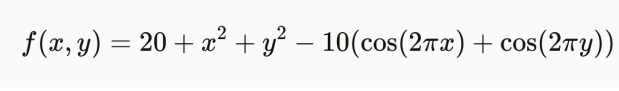

Michalewicz:

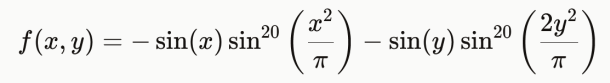





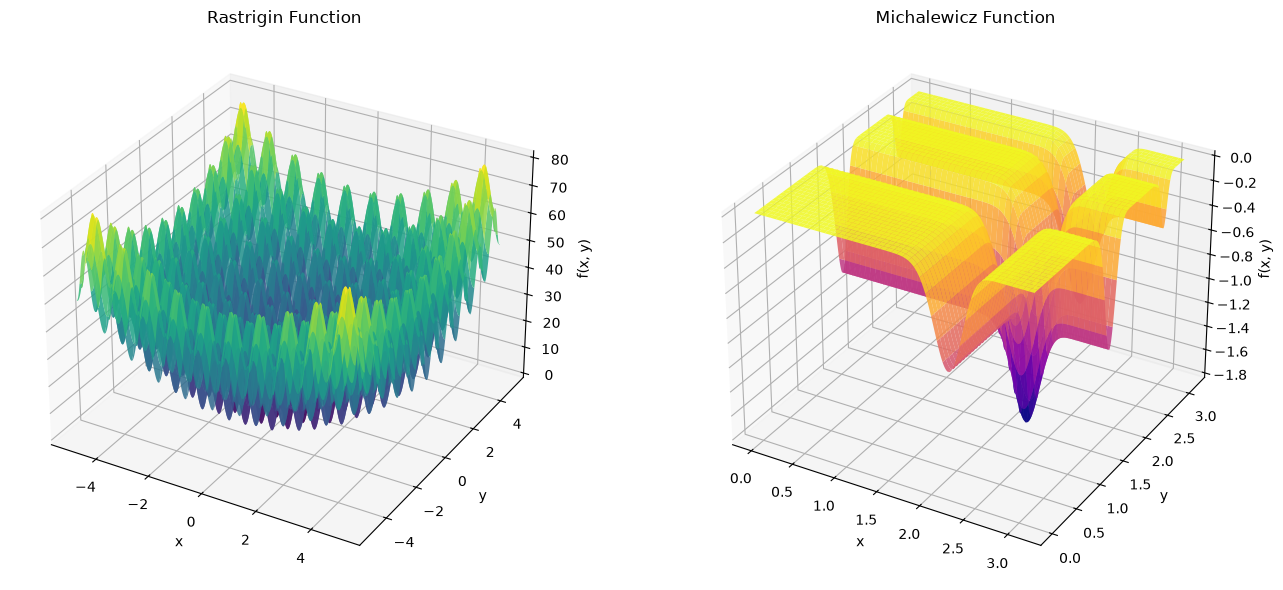

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt

def rastrigin(x, y):
    return 20 + x**2 + y**2 - 10 * (np.cos(2 * np.pi * x) + np.cos(2 * np.pi * y))

def michalewicz(x, y):
    return -np.sin(x) * (np.sin(x**2 / np.pi) ** 20) - np.sin(y) * (np.sin(2 * y**2 / np.pi) ** 20)


x_r = np.linspace(-5, 5, 1000)
y_r = np.linspace(-5, 5, 1000)
X_r, Y_r = np.meshgrid(x_r, y_r)
Z_r = rastrigin(X_r, Y_r)

x_m = np.linspace(0, np.pi, 1000)
y_m = np.linspace(0, np.pi, 1000)
X_m, Y_m = np.meshgrid(x_m, y_m)
Z_m = michalewicz(X_m, Y_m)

fig = plt.figure(figsize=(14, 6))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_surface(X_r, Y_r, Z_r, cmap='viridis', alpha=0.85, edgecolor='none')
ax1.set_title('Rastrigin Function')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('f(x, y)')

ax2 = fig.add_subplot(1, 2, 2, projection='3d')
ax2.plot_surface(X_m, Y_m, Z_m, cmap='plasma', alpha=0.85, edgecolor='none')
ax2.set_title('Michalewicz Function')
ax2.set_xlabel('x')
ax2.set_ylabel('y')
ax2.set_zlabel('f(x, y)')

plt.tight_layout()
plt.show()


What fitness landscape properties can you visually see?

### Visually Observable Properties:
- **Rastrigin Function:**
  - Contains a dense grid of many local minima and maxima.
  - The function creates a clear overall bowl shape, which leads to the global minima being in the middle, with the maxima being on the corners
  - The landscape is symmetric along both axes.
- **Michalewicz Function:**
  - **Large Plateaus:** Most of the surface is completely flat, providing no information for local search.
  - **Steep, Narrow Basins:** Contains a few deep troughs where the local and global minima lie.


## 3. Walks
Create a random walk in the solution space of the Rastrigin function and visualize it. Try to add it
to your visualization from task 2. Additionally, prepare a 2D graph of the results. The
neighbourhood structure should be pretty simple. Add/remove a constant value to x/y.


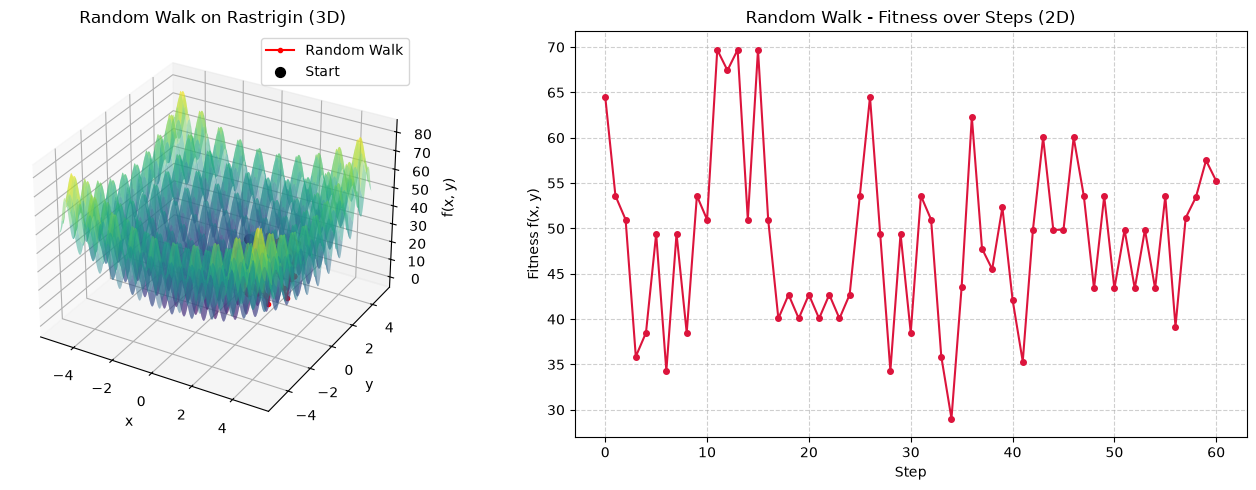

In [2]:
random.seed(42)

def get_neighbours(x, y, step=0.25, bounds=(-5, 5)):
    moves = [(step, 0), (-step, 0), (0, step), (0, -step)]
    neighbours = []
    for dx, dy in moves:
        nx = np.clip(x + dx, bounds[0], bounds[1])
        ny = np.clip(y + dy, bounds[0], bounds[1])
        neighbours.append((nx, ny))
    return neighbours

# init walk
rx, ry = 3.5, -3.5
rw_path = [(rx, ry, rastrigin(rx, ry))]

#random walk
for _ in range(60):
    rx, ry = random.choice(get_neighbours(rx, ry, step=0.3))
    rw_path.append((rx, ry, rastrigin(rx, ry)))

rw_x = [p[0] for p in rw_path]
rw_y = [p[1] for p in rw_path]
rw_z = [p[2] for p in rw_path]

fig = plt.figure(figsize=(14, 5))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_surface(X_r, Y_r, Z_r, cmap='viridis', alpha=0.45, edgecolor='none')

# random walk
ax1.plot(rw_x, rw_y, rw_z, color='red', marker='o', markersize=3, linewidth=1.5, label='Random Walk')
ax1.scatter([rw_x[0]], [rw_y[0]], [rw_z[0]], color='black', s=50, label='Start')

ax1.set_title('Random Walk on Rastrigin (3D)')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('f(x, y)')
ax1.legend()

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(rw_z, color='crimson', marker='o', markersize=4)
ax2.set_title('Random Walk - Fitness over Steps (2D)')
ax2.set_xlabel('Step')
ax2.set_ylabel('Fitness f(x, y)')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 4. Walks II
Create a up/down walk in the solution space of the Rastrigin function and visualize it. Try to add
it to your visualization from task 2. Additionally, prepare a 2D graph of the results. The
neighbourhood structure should be pretty simple. Add/remove a constant value to x/y


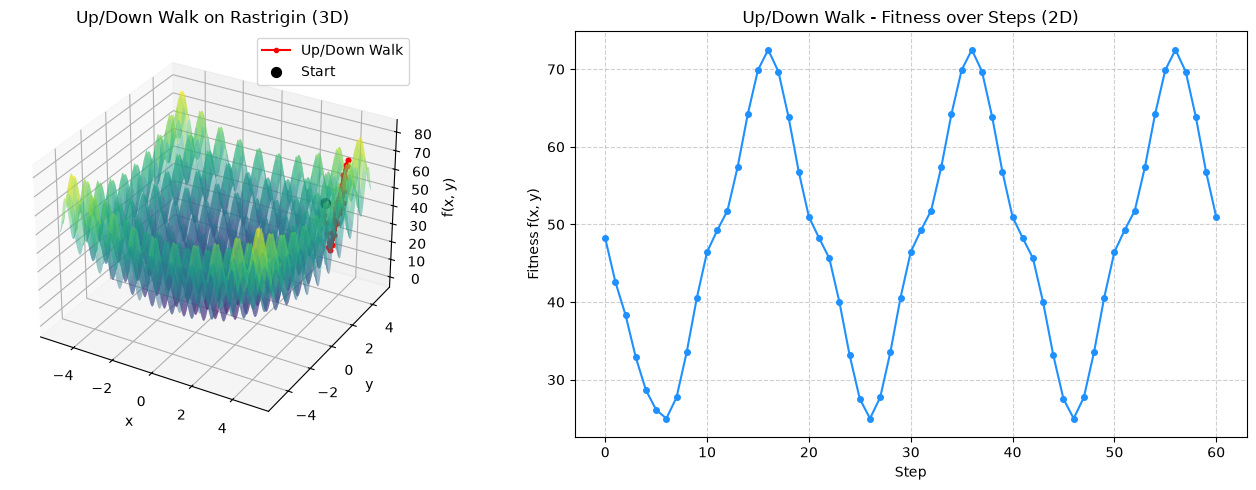

In [3]:
ux, uy = 3.6, 3.2
ud_path = [(ux, uy, rastrigin(ux, uy))]
direction = 'down'

for _ in range(60):
    neighbours = get_neighbours(ux, uy, step=0.1)
    current_z = rastrigin(ux, uy)

    if direction == 'down':
        #get best neighbor, if it is better than current, save it, else go upwards again
        best_nx, best_ny = min(neighbours, key=lambda p: rastrigin(p[0], p[1]))
        if rastrigin(best_nx, best_ny) < current_z:
            ux, uy = best_nx, best_ny
        else:
            direction = 'up'
            ux, uy = max(neighbours, key=lambda p: rastrigin(p[0], p[1]))
    else:
        best_nx, best_ny = max(neighbours, key=lambda p: rastrigin(p[0], p[1]))
        if rastrigin(best_nx, best_ny) > current_z:
            ux, uy = best_nx, best_ny
        else:
            direction = 'down'
            ux, uy = min(neighbours, key=lambda p: rastrigin(p[0], p[1]))

    ud_path.append((ux, uy, rastrigin(ux, uy)))

ud_x = [p[0] for p in ud_path]
ud_y = [p[1] for p in ud_path]
ud_z = [p[2] for p in ud_path]

fig = plt.figure(figsize=(14, 5))

ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.plot_surface(X_r, Y_r, Z_r, cmap='viridis', alpha=0.45, edgecolor='none')

# random walk
ax1.plot(ud_x, ud_y, ud_z, color='red', marker='o', markersize=3, linewidth=1.5, label='Up/Down Walk')
ax1.scatter([ud_x[0]], [ud_y[0]], [ud_z[0]], color='black', s=50, label='Start')

ax1.set_title('Up/Down Walk on Rastrigin (3D)')
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('f(x, y)')
ax1.legend()

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(ud_z, color='dodgerblue', marker='o', markersize=4)
ax2.set_title('Up/Down Walk - Fitness over Steps (2D)')
ax2.set_xlabel('Step')
ax2.set_ylabel('Fitness f(x, y)')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


AI Prompts:
- whats the size of the search space in a jssp problem using the operation-list encoding (n*m)
- create 3d visualizations for following functions """def rastrigin(x, y):
    return 20 + x**2 + y**2 - 10 * (np.cos(2 * np.pi * x) + np.cos(2 * np.pi * y))
def michalewicz(x, y):
    return -np.sin(x) * (np.sin(x**2 / np.pi) ** 20) - np.sin(y) * (np.sin(2 * y**2 / np.pi) ** 20)
""". with the interval [-5, 5] and [0, pi] with the number for points being [1000x1000]